# Évaluation de la prédiction salariale

Nous reproduisons le même découpage et la même expérience que dans le notebook 04, avec trois modèles : moyenne globale, moyenne par métier et régression Ridge.
MAE : erreur absolue moyenne en USD (plus petite = meilleure).
RMSE : erreur en USD plus sensible aux grandes erreurs.
R² : score relatif à la variabilité des cibles du test ; un score nul ou négatif
indique que le modèle explique peu ou pas cette variabilité.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
project_root = Path.cwd() if (Path.cwd() / "data/archive").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.salary_prediction import evaluate_salary_model
data_dir = project_root / "data/archive"
offres = pd.read_csv(data_dir / "fact_job_postings.csv")
liens = pd.read_csv(data_dir / "bridge_job_skills.csv")
scores, predictions = evaluate_salary_model(offres, liens)
display(scores.round(3))

,MAE_USD,RMSE_USD,R2,n_train,n_test
modele,,,,,
Reference moyenne,31452.332,36998.196,-0.000,44000,11000
Moyenne par metier,17870.604,21318.457,0.668,44000,11000
Regression Ridge,17872.053,21325.897,0.668,44000,11000


,nombre_offres,MAE_modele_USD,MAE_reference_USD,MAE_moyenne_metier_USD
experience_level,,,,
Entry,2760,17775.88,31332.72,17780.98
Lead,2784,17956.09,31214.92,17947.09
Mid,2743,17619.77,31132.48,17619.69
Senior,2713,18138.72,32141.03,18136.98


,nombre_offres,MAE_modele_USD,MAE_reference_USD,MAE_moyenne_metier_USD
country,,,,
Australia,884,17411.55,31715.21,17423.01
Brazil,840,18278.02,32094.85,18304.61
Canada,823,17672.93,30752.89,17665.46
France,888,17577.71,31387.70,17592.24
Germany,867,17693.72,31152.46,17702.36
India,841,18629.43,32189.22,18644.07
Ireland,884,17506.33,30081.85,17505.39
Netherlands,797,17585.37,31022.76,17593.08
Singapore,816,17692.95,31531.13,17673.70


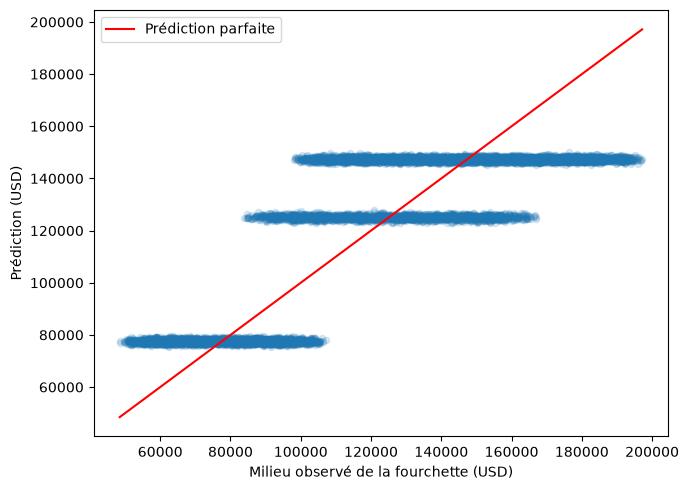

Gain de Ridge par rapport à la moyenne par métier : -1 USD de MAE


In [2]:
import matplotlib.pyplot as plt
erreurs = predictions.merge(offres[["job_id", "experience_level", "country"]], on="job_id", validate="one_to_one")
erreurs["erreur_absolue_modele"] = (erreurs["Regression Ridge"] - erreurs.salaire_cible_usd).abs()
erreurs["erreur_absolue_reference"] = (erreurs["Reference moyenne"] - erreurs.salaire_cible_usd).abs()
erreurs["erreur_absolue_metier"] = (erreurs["Moyenne par metier"] - erreurs.salaire_cible_usd).abs()
for dimension in ["experience_level", "country"]:
    display(erreurs.groupby(dimension).agg(
        nombre_offres=("job_id", "count"),
        MAE_modele_USD=("erreur_absolue_modele", "mean"),
        MAE_reference_USD=("erreur_absolue_reference", "mean"),
        MAE_moyenne_metier_USD=("erreur_absolue_metier", "mean")).round(2))
erreurs.plot.scatter(x="salaire_cible_usd", y="Regression Ridge", alpha=0.15, figsize=(7, 5))
bornes = [erreurs.salaire_cible_usd.min(), erreurs.salaire_cible_usd.max()]
plt.plot(bornes, bornes, color="red", label="Prédiction parfaite")
plt.xlabel("Milieu observé de la fourchette (USD)")
plt.ylabel("Prédiction (USD)")
plt.legend()
plt.tight_layout()
plt.show()
ecart = scores.loc["Moyenne par metier", "MAE_USD"] - scores.loc["Regression Ridge", "MAE_USD"]
print(f"Gain de Ridge par rapport à la moyenne par métier : {ecart:.0f} USD de MAE")

## Limites

Les scores concernent uniquement ce fichier et ce découpage aléatoire. Les intervalles
d'incertitude ne sont pas estimés. Les moyennes d'erreur par pays et expérience permettent
d'inspecter des écarts de performance, sans établir une équité du modèle.
Nous ne validons ni une généralisation à de nouvelles sources ni une prévision temporelle.

## Résultat mesuré sur les données du projet

Sur 44 000 offres d'entraînement et 11 000 offres de test :

| Modèle | MAE (USD) | RMSE (USD) | R² |
|---|---|---|---|
| Référence moyenne | 31 452 | 36 998 | 0,000 |
| Moyenne par métier | 17 871 | 21 318 | 0,668 |
| Régression Ridge | 17 872 | 21 326 | 0,668 |

Ridge réduit l'erreur de **43 %** par rapport à la moyenne globale, mais ne fait **pas mieux que la moyenne par métier**. Les erreurs sont semblables pour tous les pays et tous les niveaux d'expérience, ce qui confirme que ces variables n'apportent pas d'information sur le salaire.

Sur le graphique, les prédictions forment trois bandes horizontales (≈ 77 000, 125 000 et 147 000 USD), une par famille de métiers : le modèle ne sait différencier les offres que par leur métier.

**Conclusion.** Il est possible de prédire en partie le salaire d'une offre (R² = 0,67), mais uniquement grâce au métier. Ce résultat ne garantit pas la précision d'une estimation individuelle (erreur moyenne ≈ 18 000 USD) ni la validité sur un autre marché. Il concerne le milieu de la fourchette, pas le salaire effectivement versé.